In [207]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

In [208]:
ADC = AdcFitter()

In [209]:
fieldcube = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/narrowband/Ha_ch4.fits')

In [210]:
def centroid(img):
    M00 = np.sum(img)
    M10 = np.sum(img * img.grid.x)
    M01 = np.sum(img * img.grid.y)

    centroid = [M10/M00,M01/M00]
    return centroid

In [218]:
centroids = []
cropped = []

for i,field in enumerate(fieldcube):
    # crop = ADC.crop_image(field,mask_diam=0,extent=24)
    # cropped.append(crop)
    crop = field
    centroids.append(centroid(crop))

centroids = np.array(centroids).T

In [219]:
print(centroids.shape)

(2, 443)


[ 0.00829409 -0.03533197]


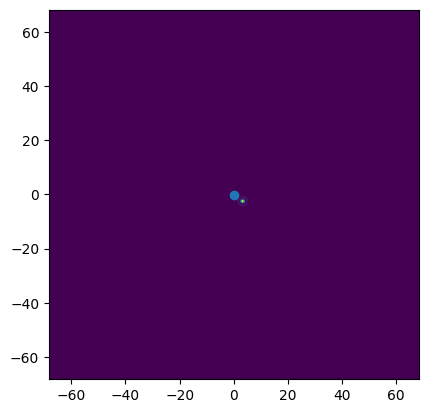

In [221]:
#imshow_field(ADC.crop_image(cropped[0],extent=20,mask_diam=0))
imshow_field(fieldcube[0])
print(centroids[:,0])
plt.scatter(centroids[0,0],centroids[1,0])

204
204


average x centroid position in Ha was 0.20066549715587242 and was 0.16406135146664233 in CH4
average y centroid position in Ha was 0.0944298103782023 and was 0.07213701533814125 in CH4
stdevs for x were 0.0627310016911402 and 0.0658287184628407 in Ha and CH4, respectively
stdevs for y were 0.059606769594322116 and 0.03862628151183615 in Ha and CH4, respectively


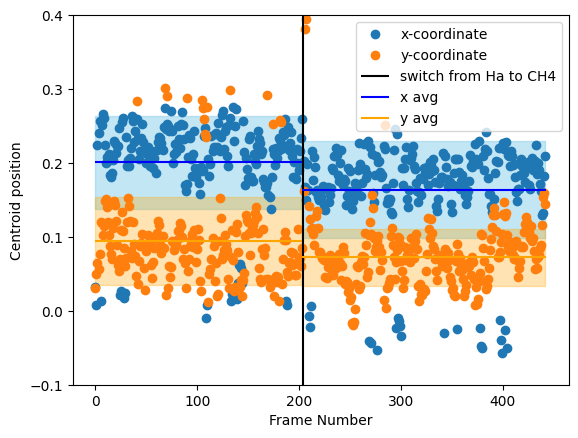

In [ ]:
frames = np.arange(443)
centroidsx = centroids[0,:]
centroidsy = centroids[1,:]

avgxha = np.mean(centroidsx[0:203])
avgyha = np.mean(centroidsy[0:203])
stdxha = np.std(centroidsx[0:203])
stdyha = np.std(centroidsy[0:203])

avgxch4 = np.mean(centroidsx[209:])
avgych4 = np.mean(centroidsy[209:])
stdxch4 = np.std(centroidsx[209:])
stdych4 = np.std(centroidsy[209:])

print(f'average x centroid position in Ha was {avgxha} and was {avgxch4} in CH4')
print(f'average y centroid position in Ha was {avgyha} and was {avgych4} in CH4')
print(f'stdevs for x were {np.std(centroidsx[0:203])} and {np.std(centroidsx[209:])} in Ha and CH4, respectively')
print(f'stdevs for y were {np.std(centroidsy[0:203])} and {np.std(centroidsy[209:])} in Ha and CH4, respectively')

plt.plot(frames,centroidsx,'o',label='x-coordinate')
plt.plot(frames,centroidsy,'o',label='y-coordinate')
plt.vlines(204,ymin=-2,ymax=2,colors='black',label='switch from Ha to CH4')
plt.hlines(avgxha,0,203,colors='blue',label='x avg')
plt.fill_between(frames[0:203],y1=avgxha + stdxha, y2=avgxha - stdxha,color='skyblue',alpha=0.5)
plt.hlines(avgyha,0,203,colors='orange',label='y avg')
plt.fill_between(frames[0:203],y1=avgyha + stdyha, y2=avgyha - stdyha,color='orange',alpha=0.3)
plt.hlines(avgxch4,203,443,colors='blue')#label='x CH4 avg')
plt.fill_between(frames[203:443],y1=avgxch4 + stdxch4, y2=avgxch4 - stdxch4,color='skyblue',alpha=0.5)
plt.hlines(avgych4,203,443,colors='orange')#,label='y CH4 avg')
plt.fill_between(frames[203:443],y1=avgych4 + stdych4, y2=avgych4 - stdych4,color='orange',alpha=0.3)
plt.ylim((-0.1,0.4))
plt.xlabel('Frame Number')
plt.ylabel('Centroid position')
plt.legend()

In [ ]:
def window_field(data, center, width, height):
    indx = data.grid.closest_to(center)
    y_ind, x_ind = np.unravel_index(indx, data.shaped.shape)
    cutout = data.shaped[(y_ind-height//2):(y_ind + height//2), (x_ind-width//2):(x_ind+width//2)]
    sub_grid = make_pupil_grid([width, height], [width * data.grid.delta[0], height * data.grid.delta[1]])
    return Field(cutout.ravel(), sub_grid)

In [241]:
peaks = []

for i,field in enumerate(fieldcube):
    peaks.append(field.grid[np.argmax(field)])

peaks = np.array(peaks).T
print(peaks.shape)

(2, 443)


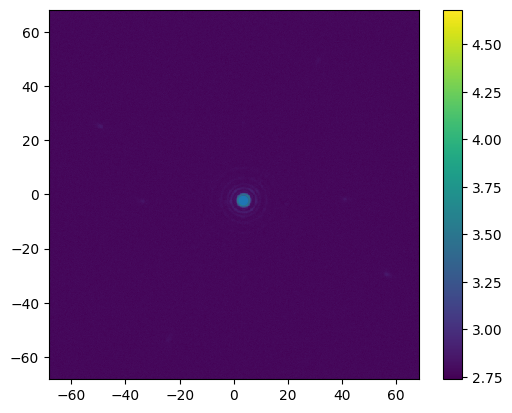

In [243]:
field = fieldcube[399]

imshow_field(np.log10(field))
plt.colorbar()
plt.scatter(peaks[0,399],peaks[1,399])
#plt.scatter(field.grid[np.argmax(field)][0],field.grid[np.argmax(field)][1])

average x centroid position in Ha was 2.8455837568754916 and was 3.4755409785679316 in CH4
average y centroid position in Ha was -2.5446774406300303 and was -2.053649941269241 in CH4
stdevs for x were 0.09692088360160142 and 0.13345771884329027 in Ha and CH4, respectively
stdevs for y were 0.045011292874255225 and 0.10485963623401377 in Ha and CH4, respectively


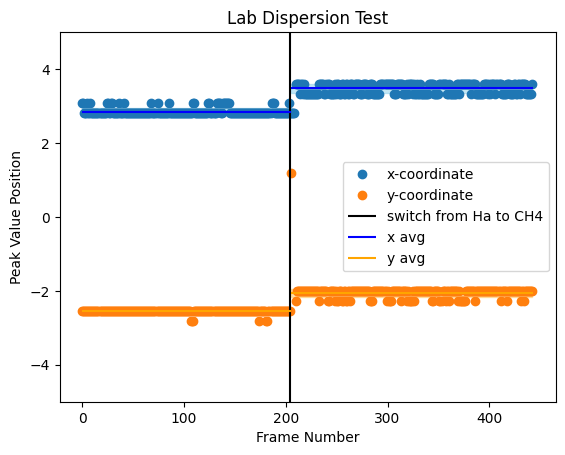

In [ ]:
#same plot as above, but using the peak image value as the metric instead of the centroid because that was giving me weird results
frames = np.arange(443)
centroidsx = peaks[0,:]
centroidsy = peaks[1,:]

avgxha = np.mean(centroidsx[0:205])
avgyha = np.mean(centroidsy[0:205])
stdxha = np.std(centroidsx[0:205])
stdyha = np.std(centroidsy[0:205])

avgxch4 = np.mean(centroidsx[212:])
avgych4 = np.mean(centroidsy[212:])
stdxch4 = np.std(centroidsx[212:])
stdych4 = np.std(centroidsy[212:])

print(f'average x peak position in Ha was {avgxha} and was {avgxch4} in CH4')
print(f'average y peak position in Ha was {avgyha} and was {avgych4} in CH4')
print(f'stdevs for x were {np.std(centroidsx[0:205])} and {np.std(centroidsx[212:])} in Ha and CH4, respectively')
print(f'stdevs for y were {np.std(centroidsy[0:205])} and {np.std(centroidsy[212:])} in Ha and CH4, respectively')

plt.plot(frames,centroidsx,'o',label='x-coordinate')
plt.plot(frames,centroidsy,'o',label='y-coordinate')
plt.vlines(204,ymin=-5,ymax=5,colors='black',label='switch from Ha to CH4')
plt.hlines(avgxha,0,205,colors='blue',label='x avg')
plt.fill_between(frames[0:205],y1=avgxha + stdxha, y2=avgxha - stdxha,color='skyblue',alpha=0.5)
plt.hlines(avgyha,0,205,colors='orange',label='y avg')
plt.fill_between(frames[0:205],y1=avgyha + stdyha, y2=avgyha - stdyha,color='orange',alpha=0.3)
plt.hlines(avgxch4,205,443,colors='blue')#label='x CH4 avg')
plt.fill_between(frames[205:443],y1=avgxch4 + stdxch4, y2=avgxch4 - stdxch4,color='skyblue',alpha=0.5)
plt.hlines(avgych4,205,443,colors='orange')#,label='y CH4 avg')
plt.fill_between(frames[205:443],y1=avgych4 + stdych4, y2=avgych4 - stdych4,color='orange',alpha=0.3)
plt.ylim((-5,5))
plt.title('Lab Dispersion Test')
plt.xlabel('Frame Number')
plt.ylabel('Peak Value Position')
plt.legend()

In [257]:
#so how much did it change?
diffx = avgxha - avgxch4
diffy = avgyha - avgych4

xpixels = diffx / (6/11)
ypixels = diffy / (6/11)

print(f'When switching from Ha to CH4, the x coordinate moves {diffx} and the y coordinate moves {diffy}')
print(f'This corresponds roughly to {xpixels} and {ypixels} pixels, respectively')

When switching from Ha to CH4, the x coordinate moves -0.6299572216924401 and the y coordinate moves -0.4910274993607895
This corresponds roughly to -1.1549215731028069 and -0.9002170821614475 pixels, respectively
